In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
    plotar_varredura_r1_a_22km,
)

tipos_noaa = carregar_noaa_por_tipo()
ow_mar = tipos_noaa["Ocean water"]
print(f"Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): {len(ow_mar)} pontos")

Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): 14363 pontos


In [2]:
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(ow_mar, max_r_km=50.0)

bacias_por_porcao = []
for val in porcoes_ativas:
    df_porcao = processar_ou_carregar_porcao(val, info, arr, label)
    if len(df_porcao) > 0:
        bacias_por_porcao.append(df_porcao)

df_bacias_globais = pd.concat(bacias_por_porcao, ignore_index=True)
df_bacias_principais = df_bacias_globais[df_bacias_globais["area_km2"] >= 100.0].reset_index(drop=True)
print(f"Porcoes processadas: {len(porcoes_ativas)} | Total bacias: {len(df_bacias_globais)} | Bacias >= 100 km2: {len(df_bacias_principais)}")

Porcoes processadas: 1061 | Total bacias: 179718 | Bacias >= 100 km2: 20168


In [3]:
pareados_por_r = {}
linhas_r = []
for r_km in range(1, 23):
    df_r = media_por_sink_raio(df_bacias_principais, ow_mar, r_km=r_km)
    pareados_por_r[r_km] = df_r
    st_u = ajustar_lei_potencia(df_r, "urban_population", "mp_mean")
    st_fu = ajustar_lei_potencia(df_r, "urban_population", "flux")
    st_t = ajustar_lei_potencia(df_r, "total_population", "mp_mean")
    st_ft = ajustar_lei_potencia(df_r, "total_population", "flux")
    linhas_r.append({
        "R_km": r_km,
        "N_urb": st_u["N"],
        "beta_urb": st_u["beta"],
        "R2_urb_pct": st_u["r2_pct"],
        "R2_flux_urb_pct": st_fu["r2_pct"],
        "N_tot": st_t["N"],
        "beta_tot": st_t["beta"],
        "R2_tot_pct": st_t["r2_pct"],
        "R2_flux_tot_pct": st_ft["r2_pct"],
    })

df_varredura = pd.DataFrame(linhas_r)
print(df_varredura.round(2).to_string(index=False))

 R_km  N_urb  beta_urb  R2_urb_pct  R2_flux_urb_pct  N_tot  beta_tot  R2_tot_pct  R2_flux_tot_pct
    1      0       NaN         NaN              NaN      0       NaN         NaN              NaN
    2      1       NaN         NaN              NaN      2       NaN         NaN              NaN
    3     15      0.37        9.51            18.62     21      0.53       20.09            38.26
    4     31      0.45       18.03            26.83     42      0.48       26.85            38.42
    5     49      0.70       33.27            42.92     65      0.54       22.85            34.55
    6     64      0.59       22.61            36.03     90      0.56       20.22            34.22
    7     81      0.54       17.77            30.13    120      0.52       17.71            30.52
    8     95      0.48       11.64            20.88    148      0.52       17.82            26.18
    9    105      0.47       11.47            20.80    171      0.50       17.11            26.90
   10    117      0.

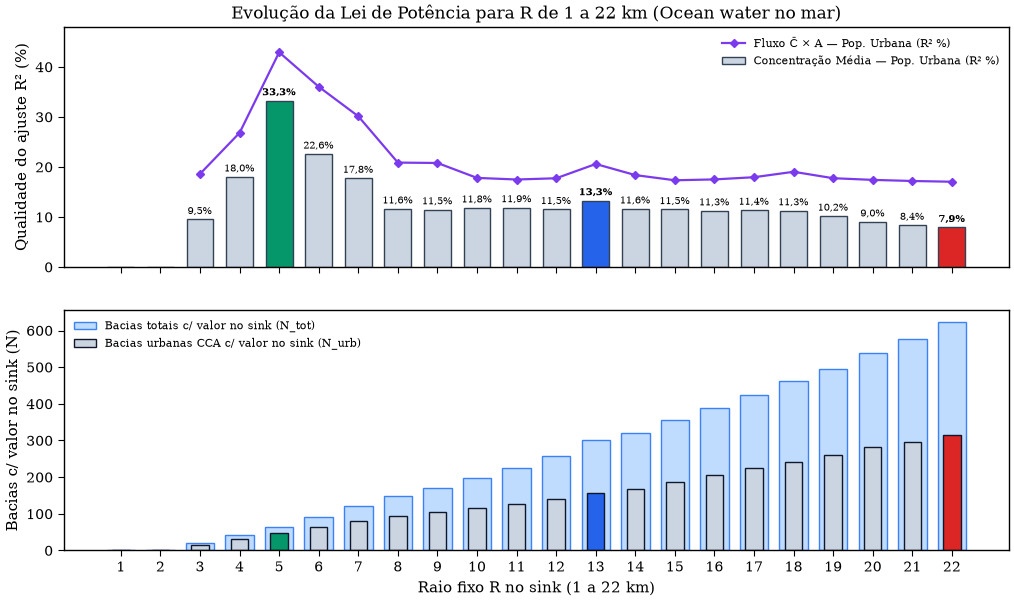

In [4]:
plotar_varredura_r1_a_22km(df_varredura)

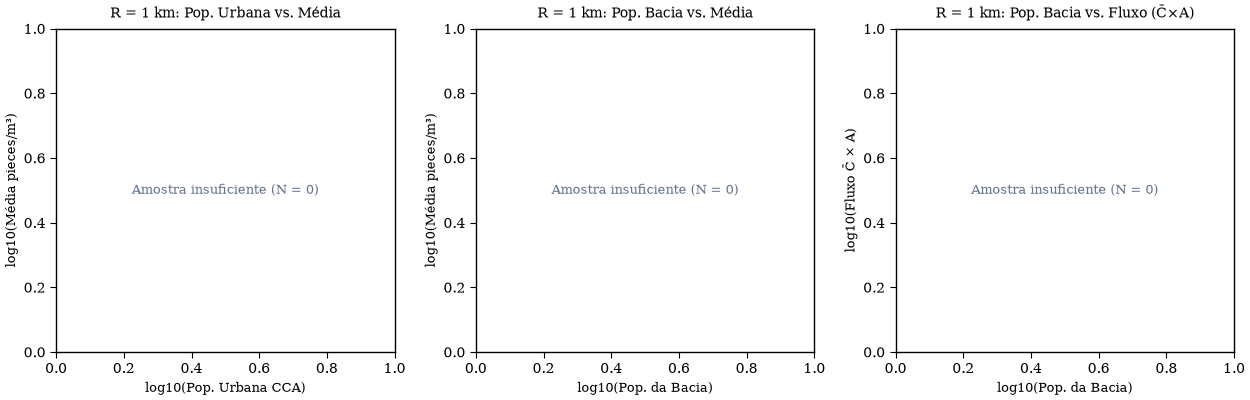

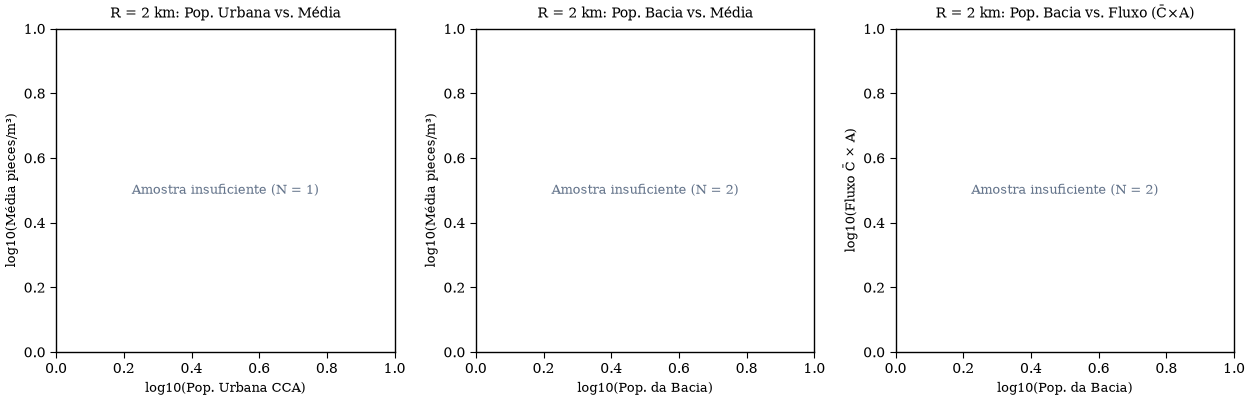

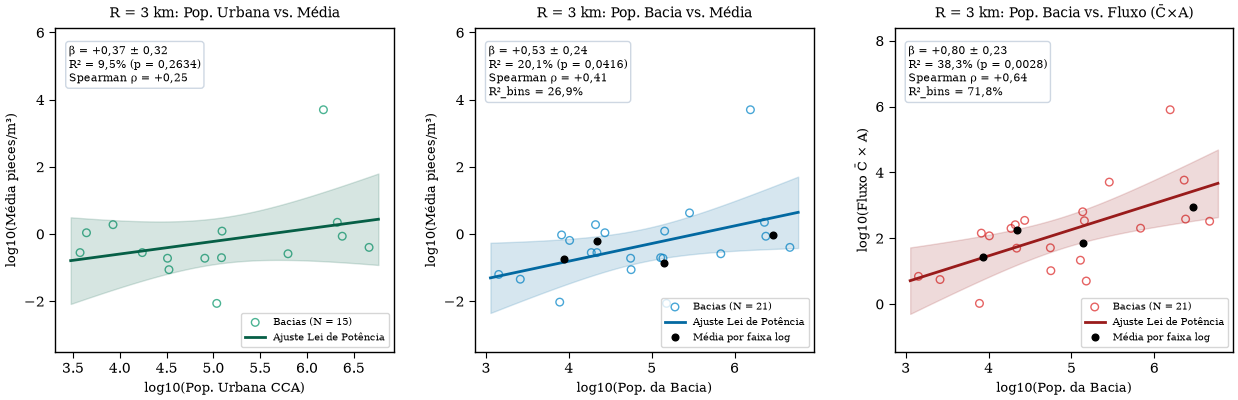

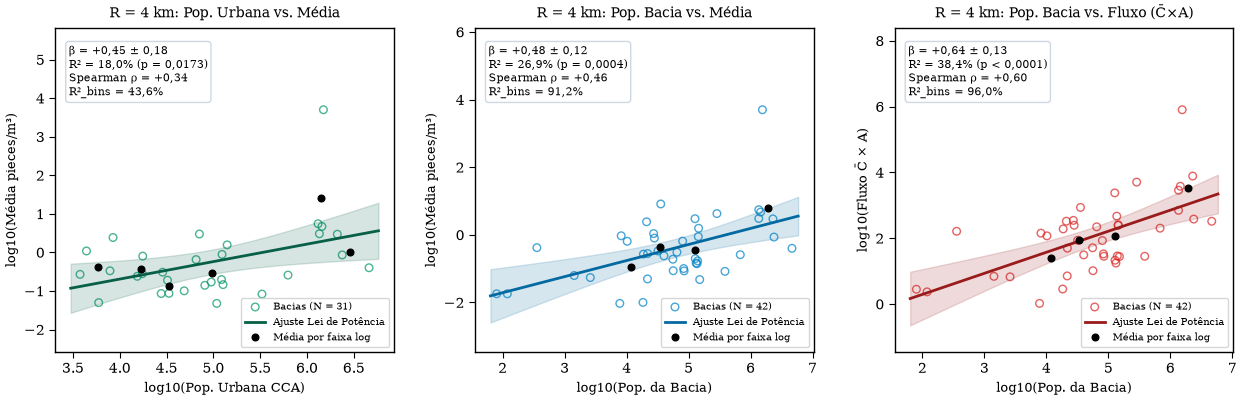

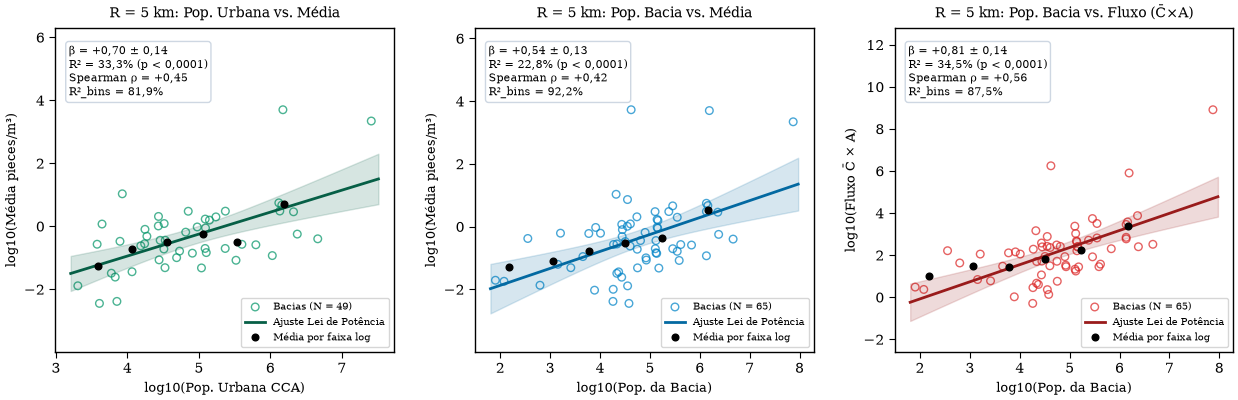

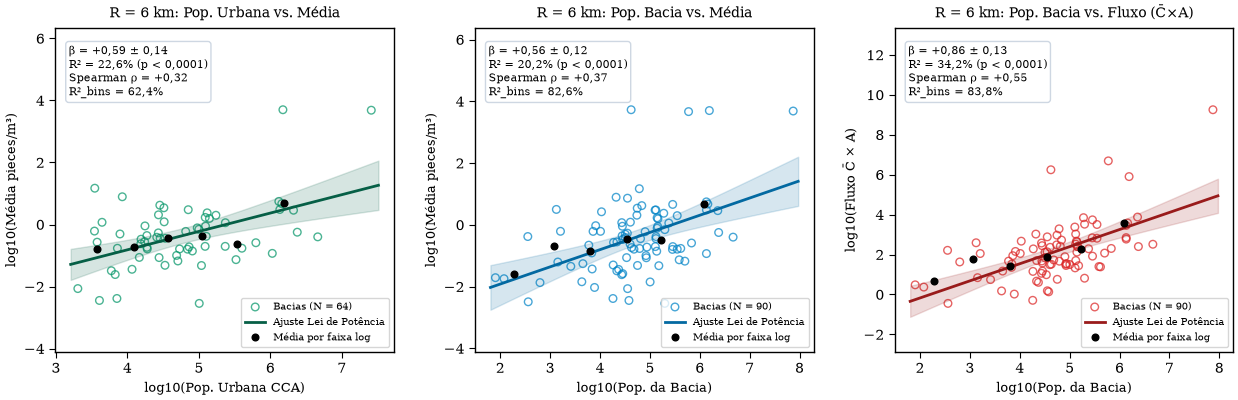

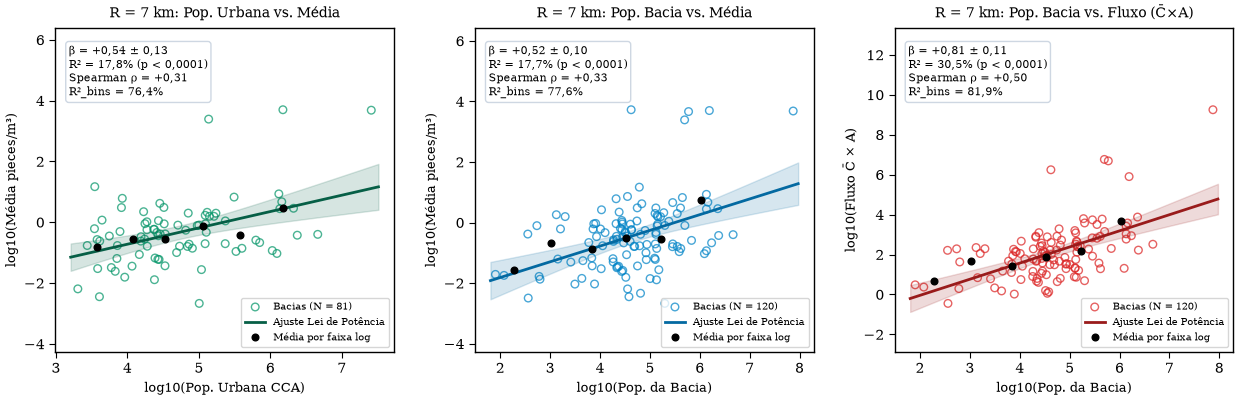

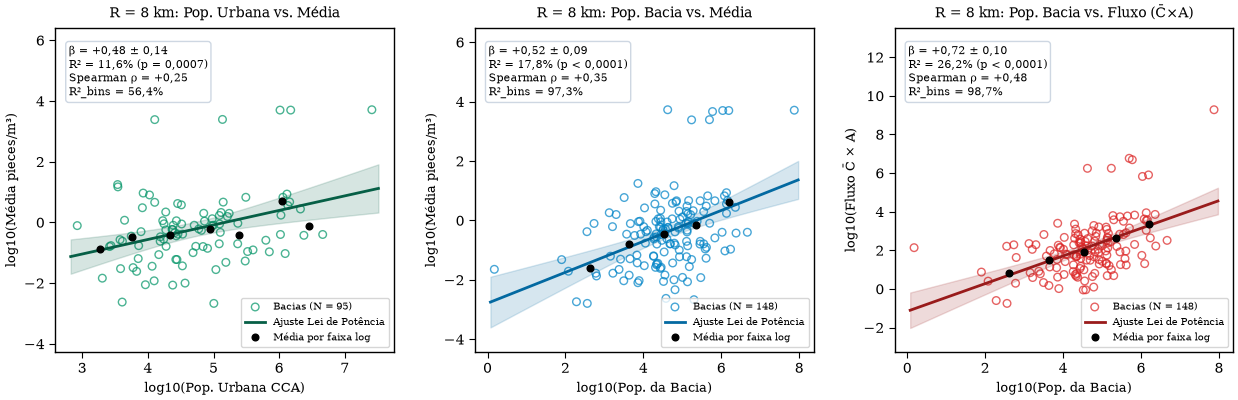

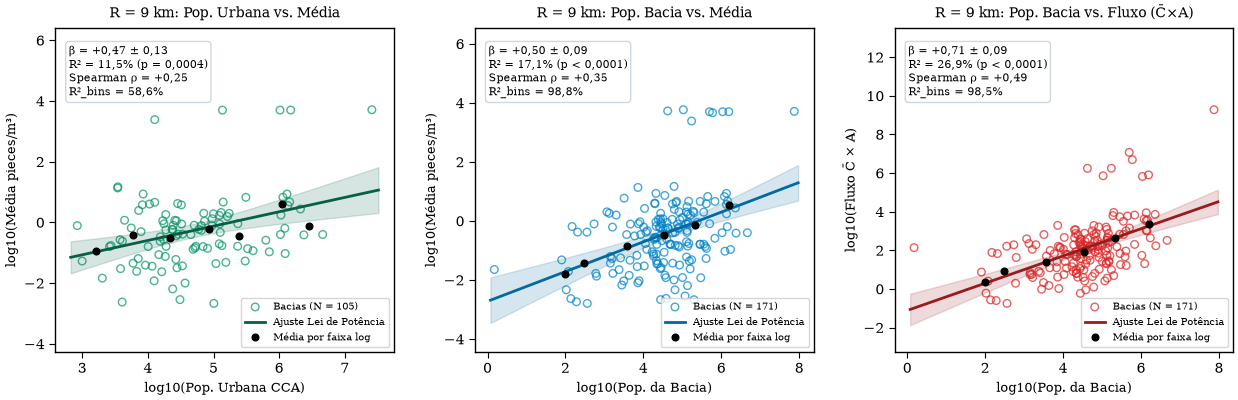

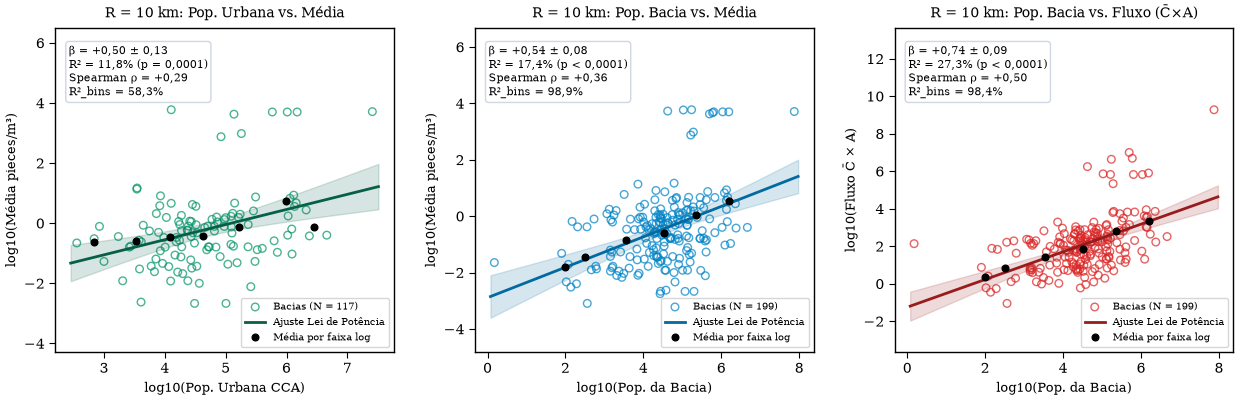

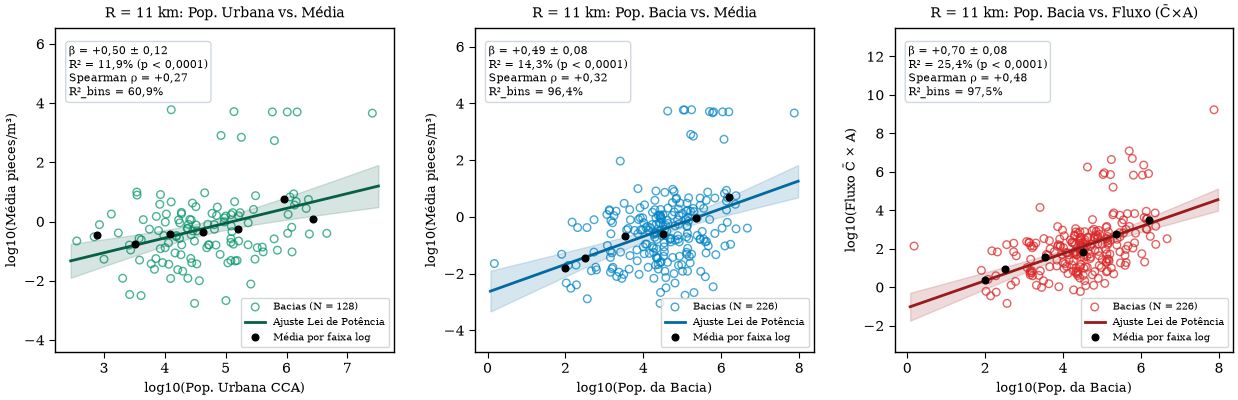

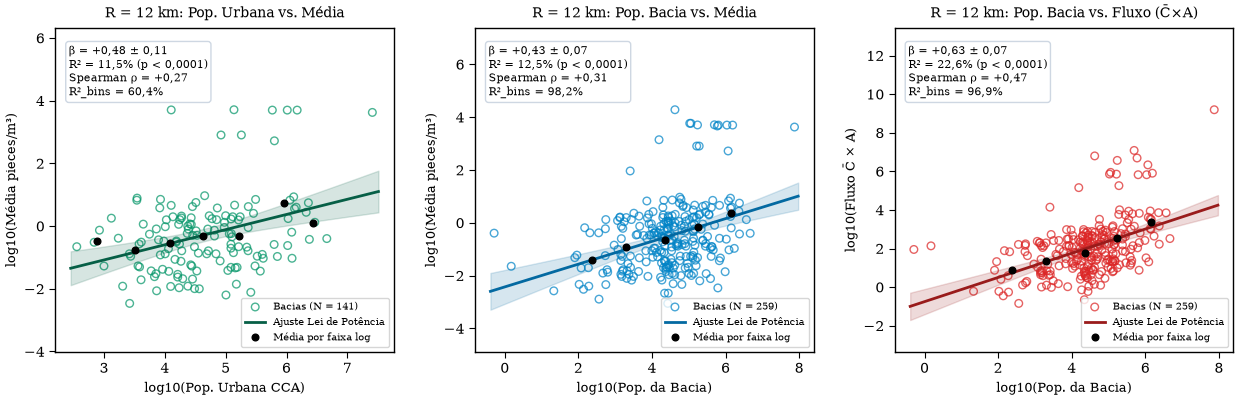

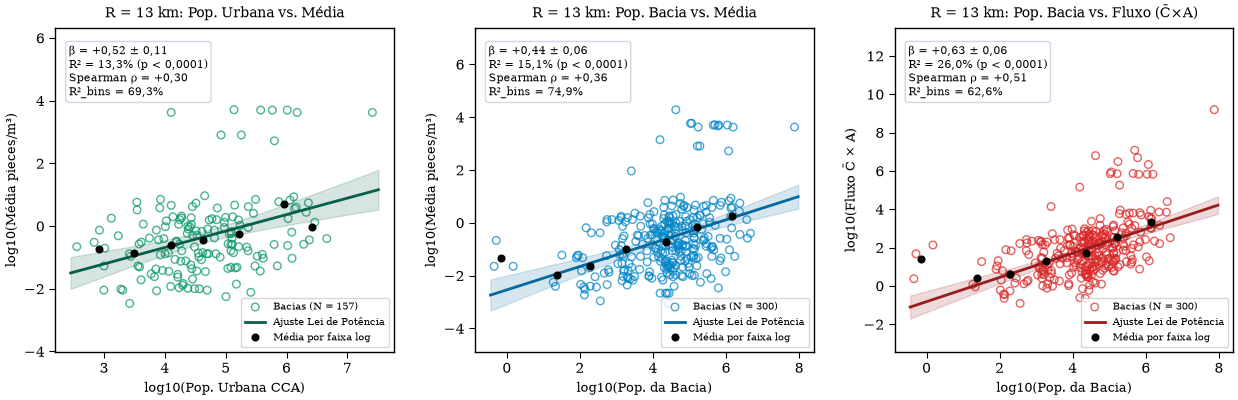

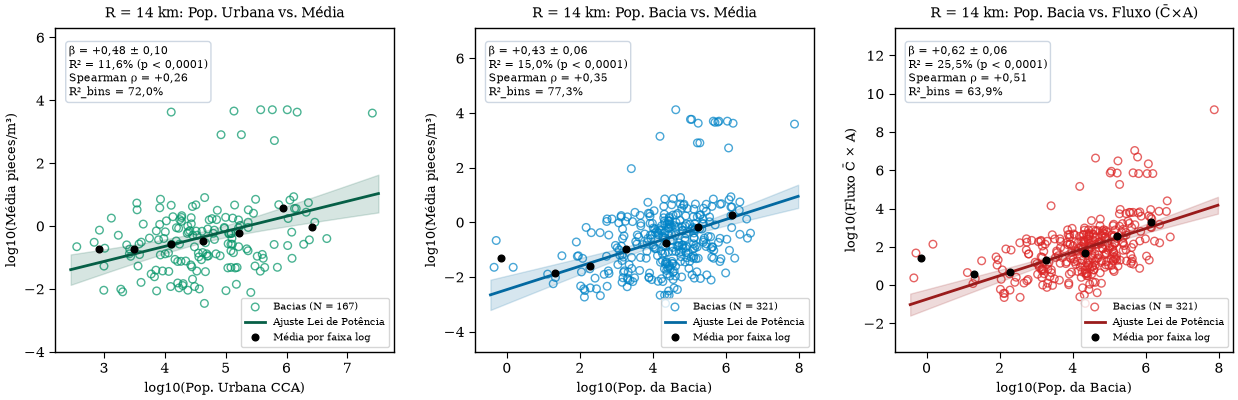

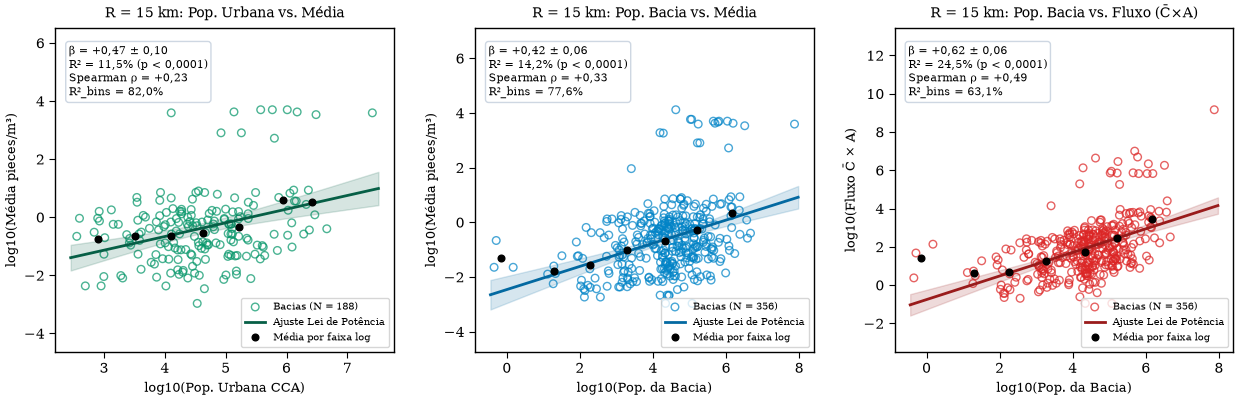

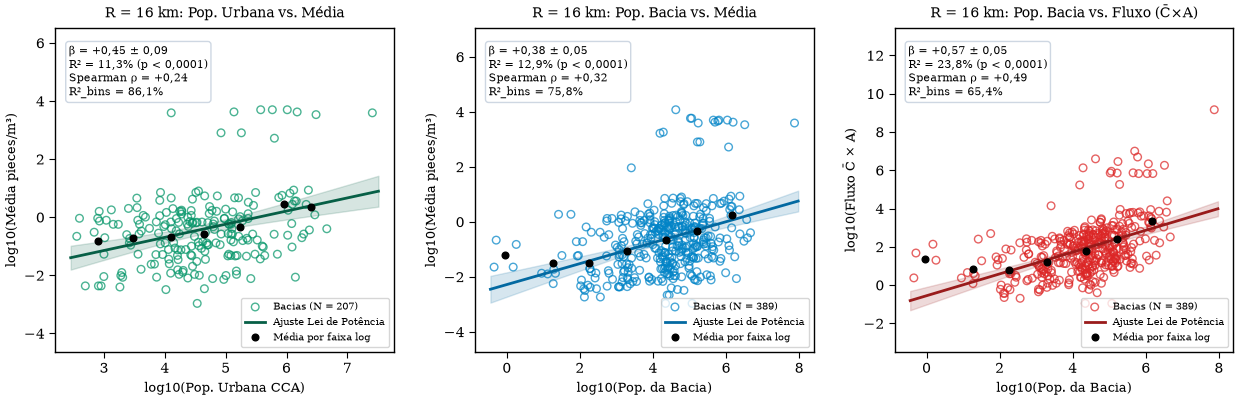

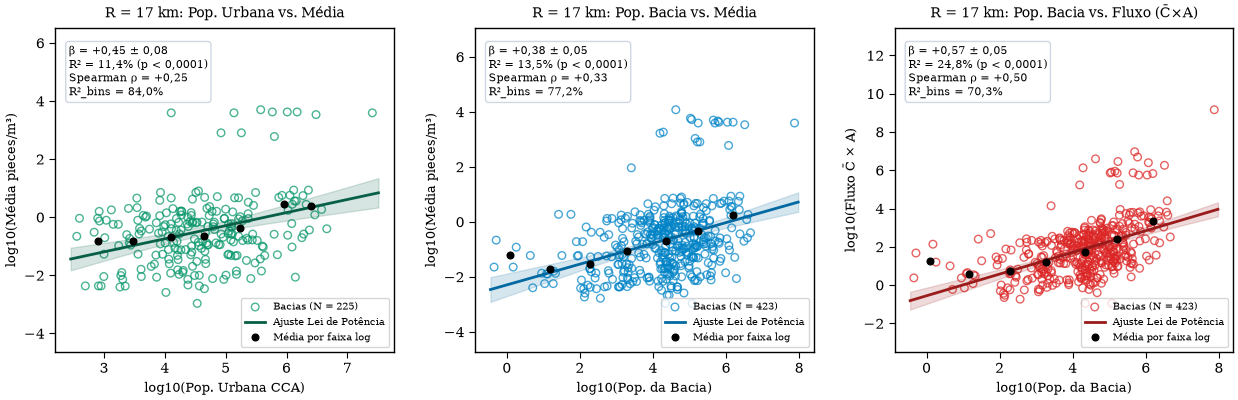

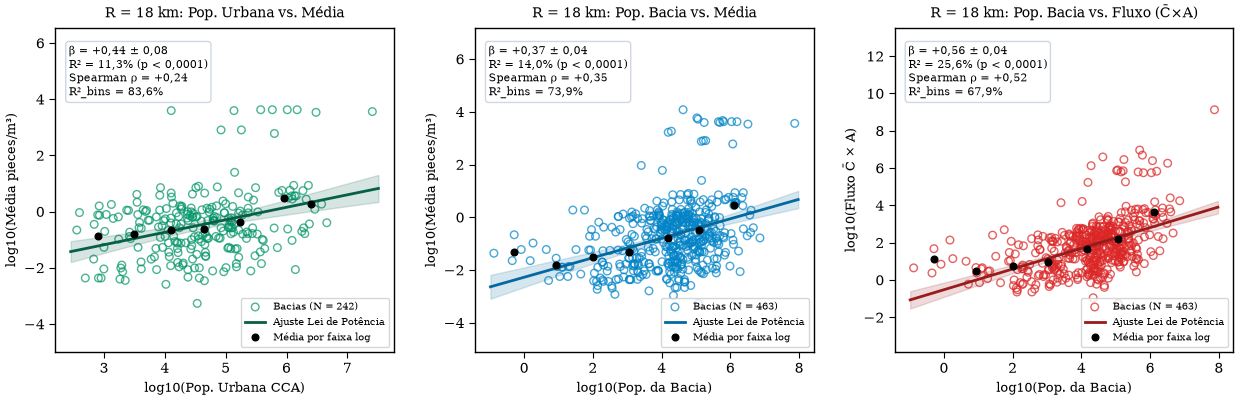

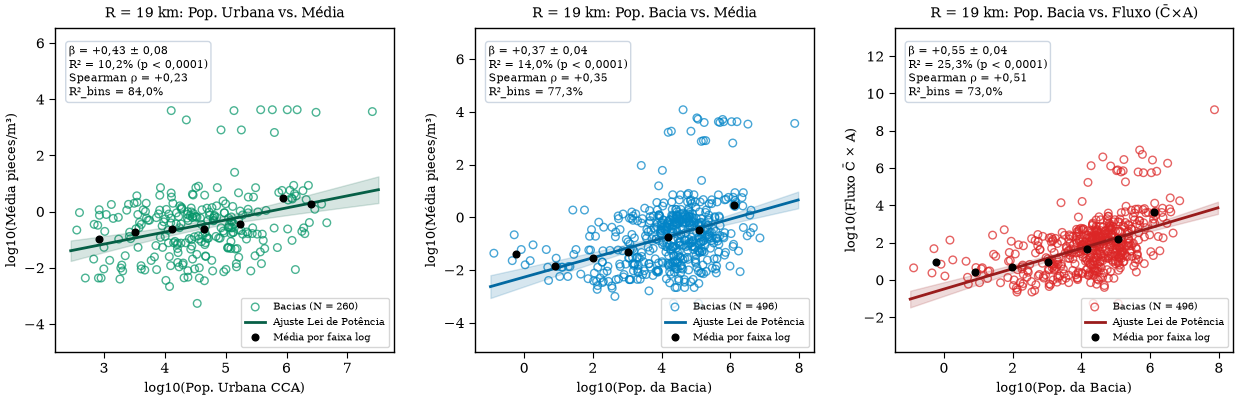

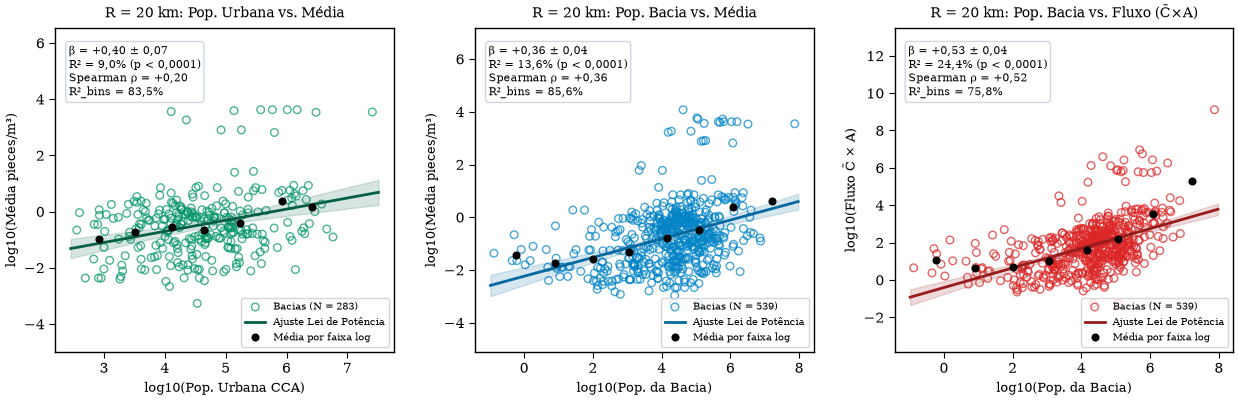

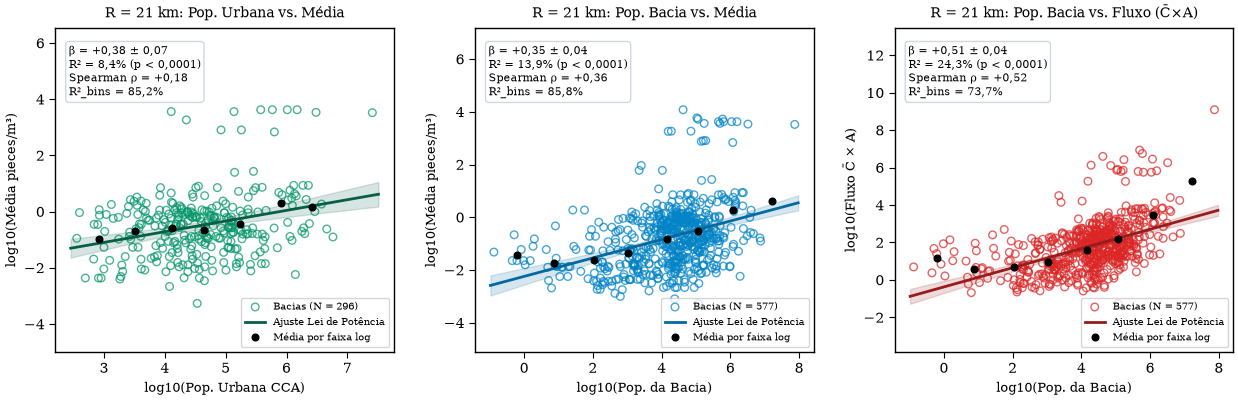

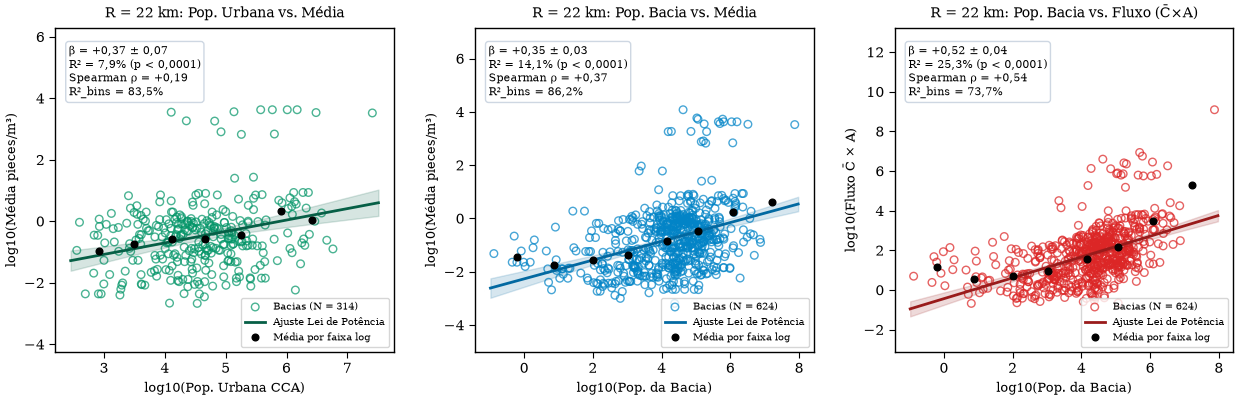

In [5]:
for r_km in range(1, 23):
    df_r = pareados_por_r[r_km]
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.2, 4.2), gridspec_kw={"wspace": 0.24})
    plotar_lei_potencia(ax1, df_r, "urban_population", "mp_mean", f"R = {r_km} km: Pop. Urbana vs. Média", "log10(Pop. Urbana CCA)", "log10(Média pieces/m³)", "#059669", "#065f46")
    plotar_lei_potencia(ax2, df_r, "total_population", "mp_mean", f"R = {r_km} km: Pop. Bacia vs. Média", "log10(Pop. da Bacia)", "log10(Média pieces/m³)", "#0284c7", "#0369a1")
    plotar_lei_potencia(ax3, df_r, "total_population", "flux", f"R = {r_km} km: Pop. Bacia vs. Fluxo (C̄×A)", "log10(Pop. da Bacia)", "log10(Fluxo C̄ × A)", "#dc2626", "#991b1b")
    plt.show()